## 1. Imports and project settings

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LogNorm
from scipy.interpolate import griddata
from IPython.display import display

# Optional: a satellite basemap requires both packages and internet access.
try:
    import geopandas as gpd
    import contextily as ctx
    HAVE_SATELLITE_MAP = True
except ImportError:
    HAVE_SATELLITE_MAP = False

# --------------------------------------------
# PROJECT FOLDERS
# --------------------------------------------

NOTEBOOK_DIR = Path.cwd().resolve()

DATA_DIR = (NOTEBOOK_DIR / "../../Data").resolve()

DGPS_FILE = DATA_DIR / "DGPS data" / "onyx_ert_92726.csv"

ERT_DIR = DATA_DIR / "ERT data"

OUTPUT_DIR = NOTEBOOK_DIR / "ERT_outputs"

N_ELECTRODES = 64
ELECTRODE_SPACING_M = 1.5
SAVE_FIGURES = True
SAVE_TABLES = True
SATELLITE_BASEMAP = True  # Set False when offline or if imagery tiles are unavailable.
MAP_ZOOM = 19

missing = [p for p in [DGPS_FILE, *ERT_FILES.values()] if not p.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing input data files:\n"
        + "\n".join(f"  - {p}" for p in missing)
        + "\nPut the notebook in the original project folder or edit PROJECT_DIR above. "
        "The uploaded notebook does not itself contain all raw CSV/DAT records."
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project directory: {PROJECT_DIR}")
print(f"Saving outputs to:  {OUTPUT_DIR}")
print("All 5 input files found.")

def save_figure(fig, filename):
    if SAVE_FIGURES:
        filepath = OUTPUT_DIR / filename
        fig.savefig(filepath, dpi=300, bbox_inches="tight")
        print(f"Saved: {filepath.name}")

Project directory: C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\Data
Saving outputs to:  C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\working_notebooks\ERT\ERT_outputs
All 5 input files found.


## 2. DGPS: load, correct labels, and align electrodes

In [4]:
dgps_raw = pd.read_csv(DGPS_FILE)
required_cols = ["Name", "Longitude", "Latitude", "Ellipsoidal height"]
missing_cols = sorted(set(required_cols) - set(dgps_raw.columns))
if missing_cols:
    raise ValueError(f"DGPS CSV is missing columns: {missing_cols}")

print("Original DGPS file — first 10 records:")
cols_to_show = [*required_cols, *(["Elevation RMS"] if "Elevation RMS" in dgps_raw else [])]
display(dgps_raw[cols_to_show].head(10))


def correct_line2_labels(dgps_input):
    '''Apply the original field naming fix before extracting either profile.'''
    result = dgps_input.copy()
    result["Name"] = result["Name"].astype(str).str.strip()
    if not (result["Name"] == "2ert_shouldbe5").any():
        print("Line 2 special naming correction not needed (marker absent).")
        return result

    # Rename from highest index downward to avoid collisions while shifting 5–15.
    # Make all changes from the original labels, not by repeatedly editing old labels.
    source_names = result["Name"].copy()
    for original in range(5, 16):
        result.loc[source_names == f"2ert{original}", "Name"] = f"2ert{original + 1}"
    result.loc[source_names == "2ert_shouldbe5", "Name"] = "2ert5"
    print("Applied Line 2 label correction: 2ert_shouldbe5 → 2ert5, old 5–15 → 6–16.")
    return result


def build_dgps_profile(dgps_input, line, n_electrodes=64, spacing_m=1.5):
    '''Return DGPS in the SAME x direction as the ABEM ERT electrode indices.'''
    if line not in (1, 2):
        raise ValueError("line must be 1 or 2")
    prefix = "ert" if line == 1 else "2ert"
    pattern = rf"{prefix}(\d+)"

    df = dgps_input.copy()
    mask = df["Name"].astype(str).str.fullmatch(pattern, na=False)
    profile = df.loc[mask].copy()
    profile["dgps_point"] = profile["Name"].str.extract(pattern)[0].astype(int)
    profile["electrode"] = n_electrodes + 1 - profile["dgps_point"]
    profile["distance_m"] = (profile["electrode"] - 1) * spacing_m
    profile["elevation_m"] = pd.to_numeric(profile["Ellipsoidal height"], errors="coerce")
    for field in ("Latitude", "Longitude"):
        profile[field] = pd.to_numeric(profile[field], errors="coerce")

    if profile.empty:
        raise ValueError(f"No DGPS records identified for line {line} with {pattern!r}")
    duplicate = profile.loc[profile["electrode"].duplicated(keep=False), ["Name", "electrode"]]
    if not duplicate.empty:
        raise ValueError(
            f"Line {line} has duplicate electrode labels after renaming:\n"
            + duplicate.to_string(index=False)
            + "\nCheck the Line 2 field correction before continuing."
        )
    if profile["electrode"].lt(1).any() or profile["electrode"].gt(n_electrodes).any():
        raise ValueError(f"Line {line}: electrode labels outside 1–{n_electrodes}")
    if profile[["elevation_m", "Latitude", "Longitude"]].isna().any().any():
        raise ValueError(f"Line {line}: invalid elevation, latitude, or longitude in DGPS records")
    profile = profile.sort_values("electrode").reset_index(drop=True)

    # Endpoints are essential for correct line orientation and an entire-line profile.
    if (profile["electrode"].iloc[0] != 1 or
            profile["electrode"].iloc[-1] != n_electrodes):
        raise ValueError(f"Line {line}: DGPS electrode 1 or {n_electrodes} is missing")
    if len(profile) < n_electrodes:
        absent = sorted(set(range(1, n_electrodes + 1)) - set(profile["electrode"]))
        print(f"WARNING — Line {line}: DGPS point(s) missing for electrodes {absent}; "
              "surface values will be interpolated between measured points.")
    return profile


dgps = correct_line2_labels(dgps_raw)
dgps1 = build_dgps_profile(dgps, line=1, n_electrodes=N_ELECTRODES,
                           spacing_m=ELECTRODE_SPACING_M)
dgps2 = build_dgps_profile(dgps, line=2, n_electrodes=N_ELECTRODES,
                           spacing_m=ELECTRODE_SPACING_M)

for line_number, profile in [(1, dgps1), (2, dgps2)]:
    print(f"Line {line_number}: {len(profile)} DGPS points; "
          f"electrode 1 = {profile.iloc[0]['Name']}, "
          f"electrode {N_ELECTRODES} = {profile.iloc[-1]['Name']}")
display(dgps1[["Name", "dgps_point", "electrode", "distance_m", "elevation_m"]].head())

if SAVE_TABLES:
    dgps1.to_csv(OUTPUT_DIR / "DGPS_Line1_aligned.csv", index=False)
    dgps2.to_csv(OUTPUT_DIR / "DGPS_Line2_aligned.csv", index=False)

Original DGPS file — first 10 records:


,Name,Longitude,Latitude,Ellipsoidal height,Elevation RMS
0,base,-106.836025,40.478782,2112.999,0.300
1,base1,-106.836009,40.478783,2114.972,NaN
2,ert1,-106.835705,40.479164,2108.275,0.254
3,ert2,-106.835701,40.479153,2108.226,0.245
4,ert3,-106.835693,40.479137,2107.967,0.263
5,ert4,-106.835687,40.479127,2108.414,0.254
6,ert5,-106.835682,40.479112,2108.764,0.232
7,ert6,-106.835674,40.479098,2109.277,0.228
8,ert7,-106.835669,40.479086,2109.051,0.220
9,ert8,-106.835660,40.479072,2109.368,0.248


Applied Line 2 label correction: 2ert_shouldbe5 → 2ert5, old 5–15 → 6–16.
Line 1: 64 DGPS points; electrode 1 = ert64, electrode 64 = ert1
Line 2: 64 DGPS points; electrode 1 = 2ert64, electrode 64 = 2ert1


,Name,dgps_point,electrode,distance_m,elevation_m
0,ert64,64,1,0.0,2114.467
1,ert63,63,2,1.5,2114.399
2,ert62,62,3,3.0,2114.497
3,ert61,61,4,4.5,2114.509
4,ert60,60,5,6.0,2114.467


Saved: DGPS_ERT_Topography.png


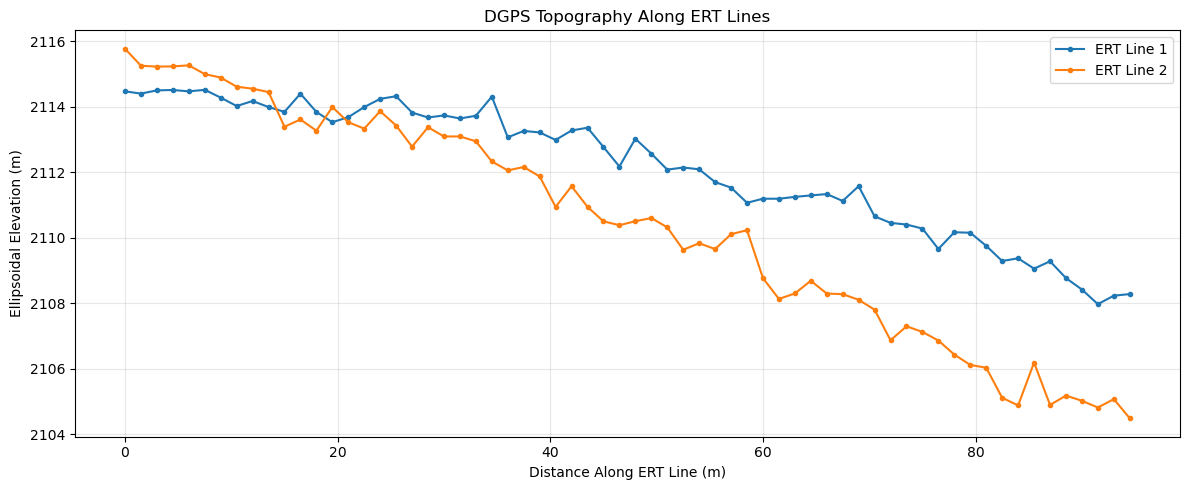

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
for profile, label in [(dgps1, "ERT Line 1"), (dgps2, "ERT Line 2")]:
    ax.plot(profile["distance_m"], profile["elevation_m"],
            marker="o", markersize=3, label=label)
ax.set(xlabel="Distance Along ERT Line (m)",
       ylabel="Ellipsoidal Elevation (m)",
       title="DGPS Topography Along ERT Lines")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
save_figure(fig, "DGPS_ERT_Topography.png")
plt.show()

## 3. Survey location: labeled DGPS map

Saved: Onyx_Mine_DGPS_Survey_Map.png


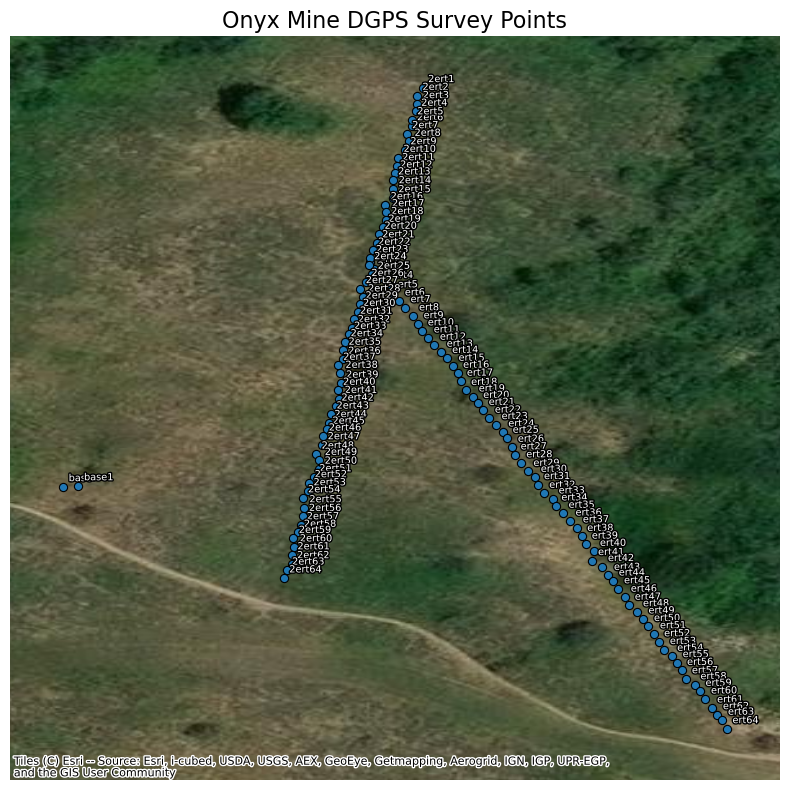

In [7]:
# Plot all valid DGPS locations, including non-ERT points, as in the original notebook.
dgps_map = dgps.copy()
for field in ("Longitude", "Latitude"):
    dgps_map[field] = pd.to_numeric(dgps_map[field], errors="coerce")
dgps_map = dgps_map.dropna(subset=["Longitude", "Latitude"]).copy()

fig, ax = plt.subplots(figsize=(8, 8))
if HAVE_SATELLITE_MAP:
    gdf = gpd.GeoDataFrame(dgps_map,
                           geometry=gpd.points_from_xy(dgps_map["Longitude"],
                                                       dgps_map["Latitude"]),
                           crs="EPSG:4326").to_crs(epsg=3857)
    map_x = gdf.geometry.x.to_numpy()
    map_y = gdf.geometry.y.to_numpy()
else:
    # The plot stays runnable without optional basemap dependencies.
    map_x = dgps_map["Longitude"].to_numpy()
    map_y = dgps_map["Latitude"].to_numpy()

ax.scatter(map_x, map_y, s=35, edgecolor="black", linewidth=0.8, zorder=3)
for x, y, name in zip(map_x, map_y, dgps_map["Name"]):
    label = ax.annotate(str(name), (x, y), xytext=(4, 4),
                        textcoords="offset points", fontsize=7,
                        color="white" if HAVE_SATELLITE_MAP else "black", zorder=4)
    if HAVE_SATELLITE_MAP:
        label.set_path_effects([pe.Stroke(linewidth=2, foreground="black"), pe.Normal()])

x_span = float(np.ptp(map_x))
y_span = float(np.ptp(map_y))
x_pad = max(0.08 * x_span, 1e-6)
y_pad = max(0.08 * y_span, 1e-6)
ax.set_xlim(map_x.min() - x_pad, map_x.max() + x_pad)
ax.set_ylim(map_y.min() - y_pad, map_y.max() + y_pad)

if SATELLITE_BASEMAP and HAVE_SATELLITE_MAP:
    try:
        ctx.add_basemap(ax, source=ctx.providers.Esri.WorldImagery, zoom=MAP_ZOOM)
    except Exception as exc:
        print(f"Satellite imagery unavailable; retaining surveyed points. Reason: {exc}")
elif SATELLITE_BASEMAP:
    print("Satellite imagery skipped: install 'geopandas' and 'contextily' to enable it.")

ax.set_title("Onyx Mine DGPS Survey Points", fontsize=16)
ax.set_axis_off()
fig.tight_layout()
save_figure(fig, "Onyx_Mine_DGPS_Survey_Map.png")
plt.show()

## 4. ABEM .dat files: parse and calculate apparent resistivity

In [8]:
ABEM_COLUMNS = [
    "n_elec", "A_x", "A_z", "B_x", "B_z",
    "M_x", "M_z", "N_x", "N_z", "resistance",
]


def read_abem_dat(filepath):
    '''Read the 10-column ABEM DAT layout used by the original notebook.'''
    filepath = Path(filepath)
    lines = filepath.read_text(encoding="utf-8", errors="replace").splitlines()
    if len(lines) < 9:
        raise ValueError(f"ABEM header is too short: {filepath}")
    try:
        title = lines[0].strip()
        spacing = float(lines[1].strip())
        measurement_type = int(lines[5].strip())
        n_measurements = int(lines[6].strip())
    except (ValueError, IndexError) as exc:
        raise ValueError(f"Unexpected ABEM header format in {filepath.name}") from exc

    measurements = []
    for n, line in enumerate(lines[9:9 + n_measurements], start=10):
        try:
            values = [float(val) for val in line.split()]
        except ValueError as exc:
            raise ValueError(f"Non-numeric value in {filepath.name}, line {n}") from exc
        if len(values) != len(ABEM_COLUMNS):
            raise ValueError(f"Expected 10 values in {filepath.name}, line {n}; got {len(values)}")
        measurements.append(values)
    if len(measurements) != n_measurements:
        raise ValueError(f"{filepath.name}: expected {n_measurements} rows; "
                         f"found {len(measurements)}")

    df = pd.DataFrame(measurements, columns=ABEM_COLUMNS)
    df.attrs.update(title=title, electrode_spacing=spacing,
                    measurement_type=measurement_type, source=filepath.name)
    return df


def calculate_apparent_resistivity(ert):
    '''Retain signed R and K; QC determines which rows are suitable for plotting.'''
    out = ert.copy()

    def separation(p, q):
        return np.hypot(out[f"{p}_x"] - out[f"{q}_x"],
                        out[f"{p}_z"] - out[f"{q}_z"])

    with np.errstate(divide="ignore", invalid="ignore"):
        factor = (1 / separation("A", "M") - 1 / separation("A", "N")
                  - 1 / separation("B", "M") + 1 / separation("B", "N"))
        out["K"] = 2 * np.pi / factor
        out["apparent_resistivity"] = out["K"] * out["resistance"]

    ab_mid = (out["A_x"] + out["B_x"]) / 2
    mn_mid = (out["M_x"] + out["N_x"]) / 2
    out["distance_m"] = (ab_mid + mn_mid) / 2
    out["pseudo_depth_m"] = np.abs(ab_mid - mn_mid) / 2
    return out


surveys = {}
for key, filepath in ERT_FILES.items():
    raw = read_abem_dat(filepath)
    if not np.isclose(raw.attrs["electrode_spacing"], ELECTRODE_SPACING_M):
        print(f"WARNING: {key} header spacing {raw.attrs['electrode_spacing']} m "
              f"differs from nominal {ELECTRODE_SPACING_M} m. "
              "Confirm geometry before inversion.")
    surveys[key] = calculate_apparent_resistivity(raw)

dd1 = surveys["dd1"]
dd2 = surveys["dd2"]
gradient_05m = surveys["gradient_05m"]
gradient_15m = surveys["gradient_15m"]

for key, survey in surveys.items():
    print(f"{key}: {len(survey)} measurements, "
          f"header spacing = {survey.attrs['electrode_spacing']} m, "
          f"measurement type = {survey.attrs['measurement_type']}")
print("\nDipole–dipole Line 1 — first five records:")
display(dd1.head())

dd1: 1980 measurements, header spacing = 1.5 m, measurement type = 1
dd2: 1980 measurements, header spacing = 1.5 m, measurement type = 1
gradient_05m: 1565 measurements, header spacing = 0.5 m, measurement type = 1
gradient_15m: 1565 measurements, header spacing = 1.5 m, measurement type = 1

Dipole–dipole Line 1 — first five records:


,n_elec,A_x,A_z,B_x,B_z,M_x,M_z,N_x,N_z,resistance,K,apparent_resistivity,distance_m,pseudo_depth_m
0,4.0,4.5,0.0,3.0,0.0,0.0,0.0,1.5,0.0,1.497830,28.274334,42.350146,2.25,1.50
1,4.0,6.0,0.0,4.5,0.0,0.0,0.0,1.5,0.0,0.247843,113.097336,28.030383,3.00,2.25
2,4.0,6.0,0.0,4.5,0.0,1.5,0.0,3.0,0.0,1.757610,28.274334,49.695252,3.75,1.50
3,4.0,7.5,0.0,6.0,0.0,0.0,0.0,1.5,0.0,0.092081,282.743339,26.035318,3.75,3.00
4,4.0,9.0,0.0,6.0,0.0,0.0,0.0,3.0,0.0,0.414660,56.548668,23.448471,4.50,3.00


## 5. Align measurement positions with DGPS surface elevation

In [9]:
def attach_topography(ert, profile):
    '''Add the plotting elevation and measured-electrode surface elevations.'''
    result = ert.copy()
    x_profile = profile["distance_m"].to_numpy()
    h_profile = profile["elevation_m"].to_numpy()
    result["surface_elevation_m"] = np.interp(result["distance_m"], x_profile, h_profile)
    result["ert_elevation_m"] = (result["surface_elevation_m"]
                                 - result["pseudo_depth_m"])
    # Retain absolute heights for later construction of topographic electrode geometry.
    for electrode in "ABMN":
        result[f"{electrode}_surface_elevation_m"] = np.interp(
            result[f"{electrode}_x"], x_profile, h_profile
        )
    return result


dd1 = attach_topography(dd1, dgps1)
dd2 = attach_topography(dd2, dgps2)
surveys["dd1"] = dd1
surveys["dd2"] = dd2

show_cols = ["distance_m", "pseudo_depth_m", "surface_elevation_m",
             "ert_elevation_m", "apparent_resistivity"]
print("Line 1 apparent resistivity with DGPS topography:")
display(dd1[show_cols].head(10))

Line 1 apparent resistivity with DGPS topography:


,distance_m,pseudo_depth_m,surface_elevation_m,ert_elevation_m,apparent_resistivity
0,2.25,1.50,2114.448,2112.948,42.350146
1,3.00,2.25,2114.497,2112.247,28.030383
2,3.75,1.50,2114.503,2113.003,49.695252
3,3.75,3.00,2114.503,2111.503,26.035318
4,4.50,3.00,2114.509,2111.509,23.448471
5,4.50,2.25,2114.509,2112.259,23.760393
6,4.50,3.75,2114.509,2110.759,23.529844
7,5.25,4.50,2114.488,2109.988,25.619501
8,5.25,1.50,2114.488,2112.988,33.519788
9,5.25,3.00,2114.488,2111.488,20.055494


In [10]:
# Original notebook diagnostics, combined into one cell.
for name, ert in [("Dipole-Dipole Line 1", dd1), ("Dipole-Dipole Line 2", dd2)]:
    print(f"\n{name}")
    print(ert.attrs)
    print("Shape:", ert.shape)
    for electrode in "ABMN":
        print(f"{electrode} x range: {ert[f'{electrode}_x'].min():.2f} to "
              f"{ert[f'{electrode}_x'].max():.2f} m")
    print(f"Resistance range: {ert['resistance'].min():.6g} to "
          f"{ert['resistance'].max():.6g} Ω")
    display(ert.head())

print("Line 1 geometric factor and apparent resistivity — first 20 rows:")
display(dd1[["A_x", "B_x", "M_x", "N_x", "resistance", "K",
             "apparent_resistivity", "distance_m", "pseudo_depth_m"]].head(20))

print("\nBasic QC (measurements are NOT rejected from the exported tables):")
qc_rows = []
for name, data in surveys.items():
    rho = data["apparent_resistivity"].to_numpy()
    valid = np.isfinite(rho) & (rho > 0)
    qc_rows.append({"survey": name, "total_rows": len(data),
                    "finite_positive_rho_a": int(valid.sum()),
                    "nonpositive_or_nonfinite": int((~valid).sum()),
                    "rho_a_min_valid_ohm_m": float(np.min(rho[valid])) if valid.any() else np.nan,
                    "rho_a_max_valid_ohm_m": float(np.max(rho[valid])) if valid.any() else np.nan})
qc_table = pd.DataFrame(qc_rows)
display(qc_table)


Dipole-Dipole Line 1
{'title': 'Project25 DipoleDipole_1', 'electrode_spacing': 1.5, 'measurement_type': 1, 'source': 'DipoleDipole_1-2023-03-07-214954.dat'}
Shape: (1980, 20)
A x range: 4.50 to 94.50 m
B x range: 3.00 to 93.00 m
M x range: 0.00 to 90.00 m
N x range: 1.50 to 91.50 m
Resistance range: 0.00124613 to 3.34977 Ω


,n_elec,A_x,A_z,B_x,B_z,M_x,M_z,N_x,N_z,resistance,K,apparent_resistivity,distance_m,pseudo_depth_m,surface_elevation_m,ert_elevation_m,A_surface_elevation_m,B_surface_elevation_m,M_surface_elevation_m,N_surface_elevation_m
0,4.0,4.5,0.0,3.0,0.0,0.0,0.0,1.5,0.0,1.497830,28.274334,42.350146,2.25,1.50,2114.448,2112.948,2114.509,2114.497,2114.467,2114.399
1,4.0,6.0,0.0,4.5,0.0,0.0,0.0,1.5,0.0,0.247843,113.097336,28.030383,3.00,2.25,2114.497,2112.247,2114.467,2114.509,2114.467,2114.399
2,4.0,6.0,0.0,4.5,0.0,1.5,0.0,3.0,0.0,1.757610,28.274334,49.695252,3.75,1.50,2114.503,2113.003,2114.467,2114.509,2114.399,2114.497
3,4.0,7.5,0.0,6.0,0.0,0.0,0.0,1.5,0.0,0.092081,282.743339,26.035318,3.75,3.00,2114.503,2111.503,2114.514,2114.467,2114.467,2114.399
4,4.0,9.0,0.0,6.0,0.0,0.0,0.0,3.0,0.0,0.414660,56.548668,23.448471,4.50,3.00,2114.509,2111.509,2114.276,2114.467,2114.467,2114.497



Dipole-Dipole Line 2
{'title': 'Project25 DipoleDipole_2', 'electrode_spacing': 1.5, 'measurement_type': 1, 'source': 'DipoleDipole_2-2023-03-07-214927.dat'}
Shape: (1980, 20)
A x range: 4.50 to 94.50 m
B x range: 3.00 to 93.00 m
M x range: 0.00 to 90.00 m
N x range: 1.50 to 91.50 m
Resistance range: 0.00193907 to 5.50781 Ω


,n_elec,A_x,A_z,B_x,B_z,M_x,M_z,N_x,N_z,resistance,K,apparent_resistivity,distance_m,pseudo_depth_m,surface_elevation_m,ert_elevation_m,A_surface_elevation_m,B_surface_elevation_m,M_surface_elevation_m,N_surface_elevation_m
0,4.0,4.5,0.0,3.0,0.0,0.0,0.0,1.5,0.0,4.792730,28.274334,135.511248,2.25,1.50,2115.2365,2113.7365,2115.229,2115.223,2115.767,2115.250
1,4.0,6.0,0.0,4.5,0.0,0.0,0.0,1.5,0.0,0.453241,113.097336,51.260349,3.00,2.25,2115.2230,2112.9730,2115.262,2115.229,2115.767,2115.250
2,4.0,6.0,0.0,4.5,0.0,1.5,0.0,3.0,0.0,4.878790,28.274334,137.944537,3.75,1.50,2115.2260,2113.7260,2115.262,2115.229,2115.250,2115.223
3,4.0,7.5,0.0,6.0,0.0,0.0,0.0,1.5,0.0,0.110217,282.743339,31.163123,3.75,3.00,2115.2260,2112.2260,2114.995,2115.262,2115.767,2115.250
4,4.0,9.0,0.0,6.0,0.0,0.0,0.0,3.0,0.0,0.671809,56.548668,37.989904,4.50,3.00,2115.2290,2112.2290,2114.888,2115.262,2115.767,2115.223


Line 1 geometric factor and apparent resistivity — first 20 rows:


,A_x,B_x,M_x,N_x,resistance,K,apparent_resistivity,distance_m,pseudo_depth_m
0,4.5,3.0,0.0,1.5,1.497830,28.274334,42.350146,2.25,1.50
1,6.0,4.5,0.0,1.5,0.247843,113.097336,28.030383,3.00,2.25
2,6.0,4.5,1.5,3.0,1.757610,28.274334,49.695252,3.75,1.50
3,7.5,6.0,0.0,1.5,0.092081,282.743339,26.035318,3.75,3.00
4,9.0,6.0,0.0,3.0,0.414660,56.548668,23.448471,4.50,3.00
5,7.5,6.0,1.5,3.0,0.210088,113.097336,23.760393,4.50,2.25
6,9.0,7.5,0.0,1.5,0.041610,565.486678,23.529844,4.50,3.75
7,10.5,9.0,0.0,1.5,0.025889,989.601686,25.619501,5.25,4.50
8,7.5,6.0,3.0,4.5,1.185520,28.274334,33.519788,5.25,1.50
9,9.0,7.5,1.5,3.0,0.070932,282.743339,20.055494,5.25,3.00



Basic QC (measurements are NOT rejected from the exported tables):


,survey,total_rows,finite_positive_rho_a,nonpositive_or_nonfinite,rho_a_min_valid_ohm_m,rho_a_max_valid_ohm_m
0,dd1,1980,1980,0,15.362492,94.712515
1,dd2,1980,1980,0,14.843092,164.186003
2,gradient_05m,1565,1565,0,24.898035,240.736412
3,gradient_15m,1565,1539,26,17.219767,13927.227442


## 6. Dipole–dipole data visualizations

Saved: DipoleDipole_Line1_Raw_Pseudosection.png


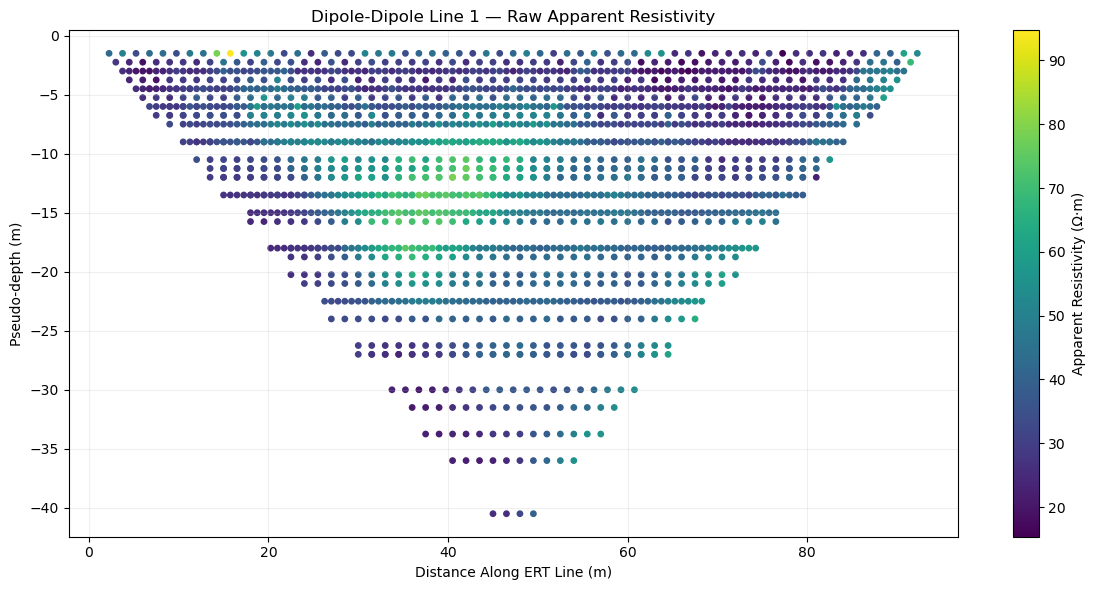

Saved: DipoleDipole_Line1_DGPS_Scatter.png


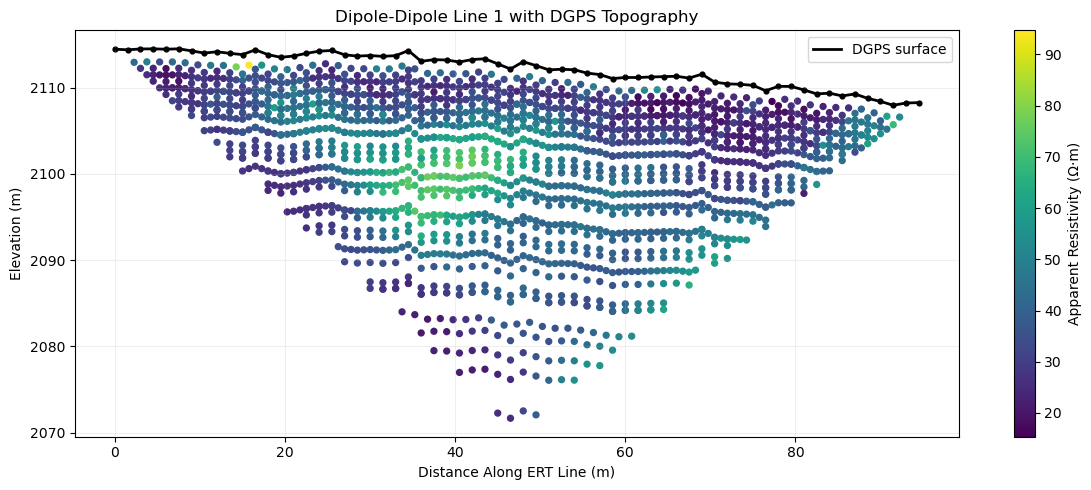

Saved: DipoleDipole_Line2_Raw_Pseudosection.png


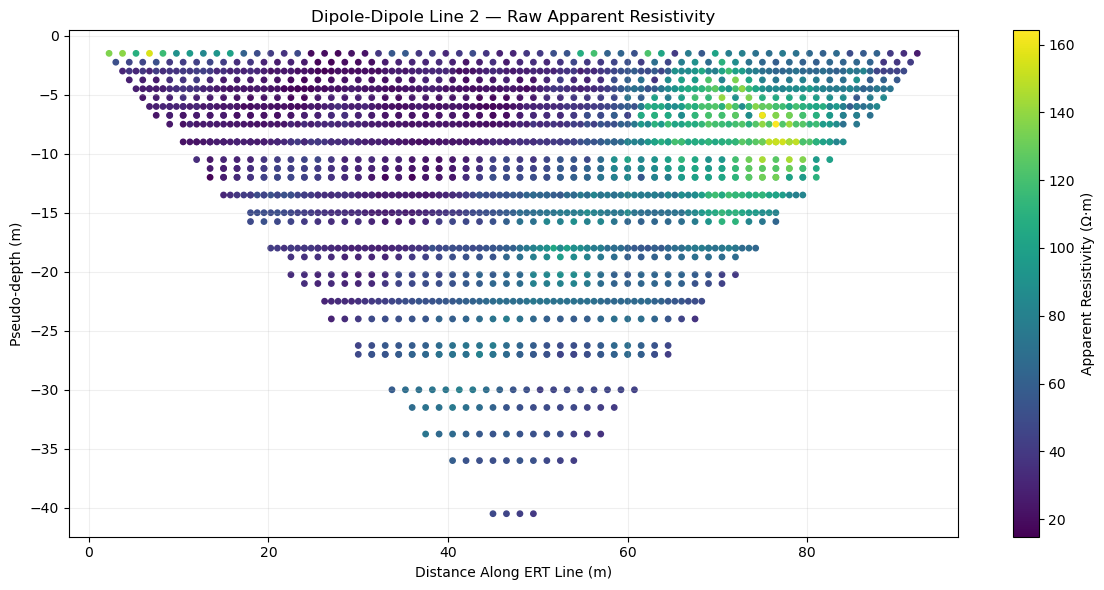

Saved: DipoleDipole_Line2_DGPS_Scatter.png


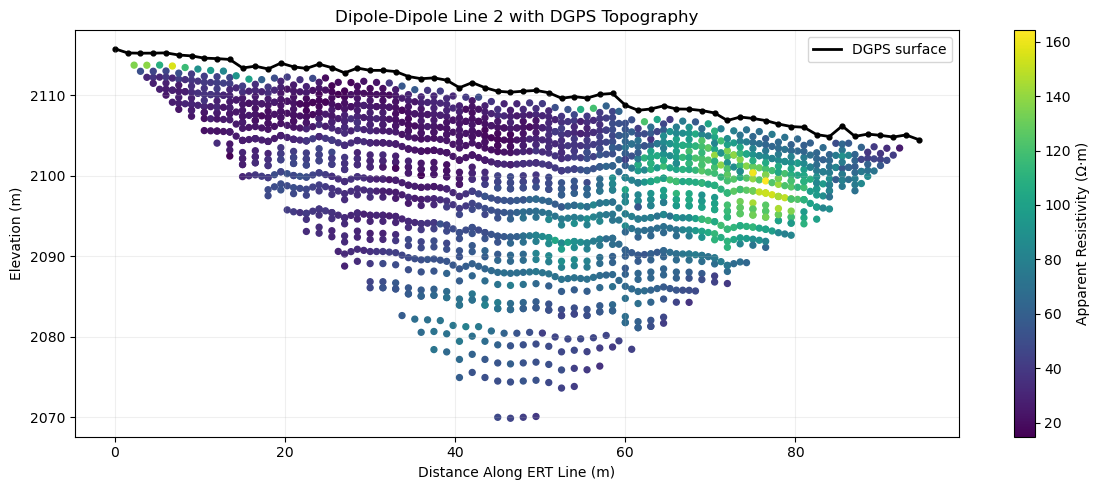

In [11]:
def plot_raw_pseudosection(ert, line):
    '''Plot actual data symbols versus *plotting* pseudodepth (not model depth).'''
    valid = ert.loc[np.isfinite(ert["apparent_resistivity"])
                    & np.isfinite(ert["distance_m"])
                    & np.isfinite(ert["pseudo_depth_m"])
                    & (ert["apparent_resistivity"] > 0)]
    fig, ax = plt.subplots(figsize=(12, 6))
    sc = ax.scatter(valid["distance_m"], -valid["pseudo_depth_m"],
                    c=valid["apparent_resistivity"], s=15)
    fig.colorbar(sc, ax=ax).set_label("Apparent Resistivity (Ω·m)")
    ax.set(xlabel="Distance Along ERT Line (m)",
           ylabel="Pseudo-depth (m)",
           title=f"Dipole-Dipole Line {line} — Raw Apparent Resistivity")
    ax.grid(alpha=0.2)
    fig.tight_layout()
    save_figure(fig, f"DipoleDipole_Line{line}_Raw_Pseudosection.png")
    plt.show()


def plot_topography_scatter(ert, profile, line):
    '''Plot individual rho-a data locations with the DGPS profile.'''
    valid = ert.loc[np.isfinite(ert["ert_elevation_m"])
                    & np.isfinite(ert["apparent_resistivity"])
                    & (ert["apparent_resistivity"] > 0)]
    fig, ax = plt.subplots(figsize=(12, 5))
    sc = ax.scatter(valid["distance_m"], valid["ert_elevation_m"],
                    c=valid["apparent_resistivity"], s=18)
    ax.plot(profile["distance_m"], profile["elevation_m"],
            color="black", linewidth=2, label="DGPS surface")
    ax.scatter(profile["distance_m"], profile["elevation_m"],
               color="black", s=12)
    fig.colorbar(sc, ax=ax).set_label("Apparent Resistivity (Ω·m)")
    ax.set(xlabel="Distance Along ERT Line (m)", ylabel="Elevation (m)",
           title=f"Dipole-Dipole Line {line} with DGPS Topography")
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    save_figure(fig, f"DipoleDipole_Line{line}_DGPS_Scatter.png")
    plt.show()


# Line 1 raw apparent resistivity and DGPS overlay replicate the original outputs.
# Line 2 equivalents are included for consistent survey comparison.
for line, ert, profile in [(1, dd1, dgps1), (2, dd2, dgps2)]:
    plot_raw_pseudosection(ert, line)
    plot_topography_scatter(ert, profile, line)

## 7. Smooth pseudosections with DGPS and orientation

Saved: DipoleDipole_Line1_Pseudosection.png


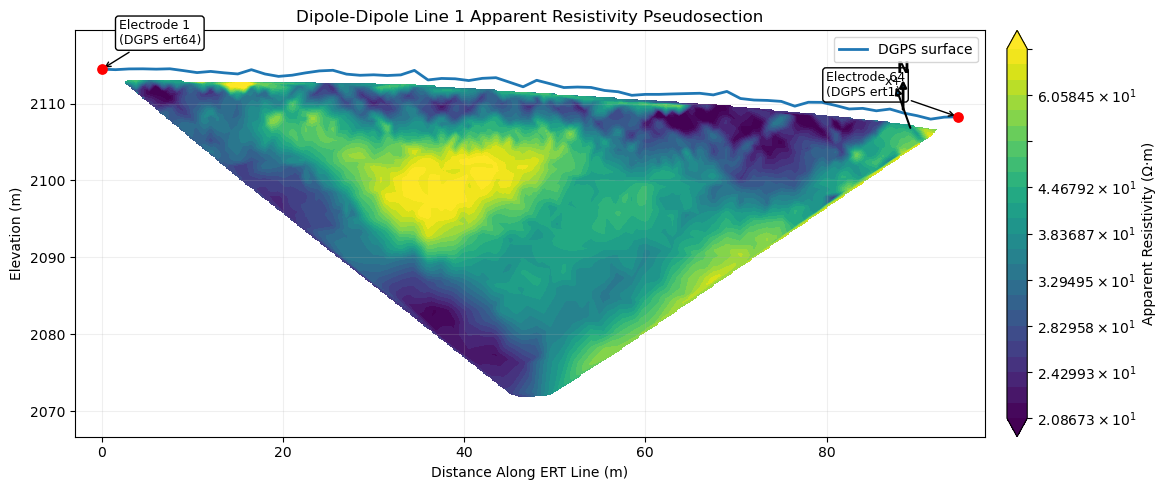

Saved: DipoleDipole_Line2_Pseudosection.png


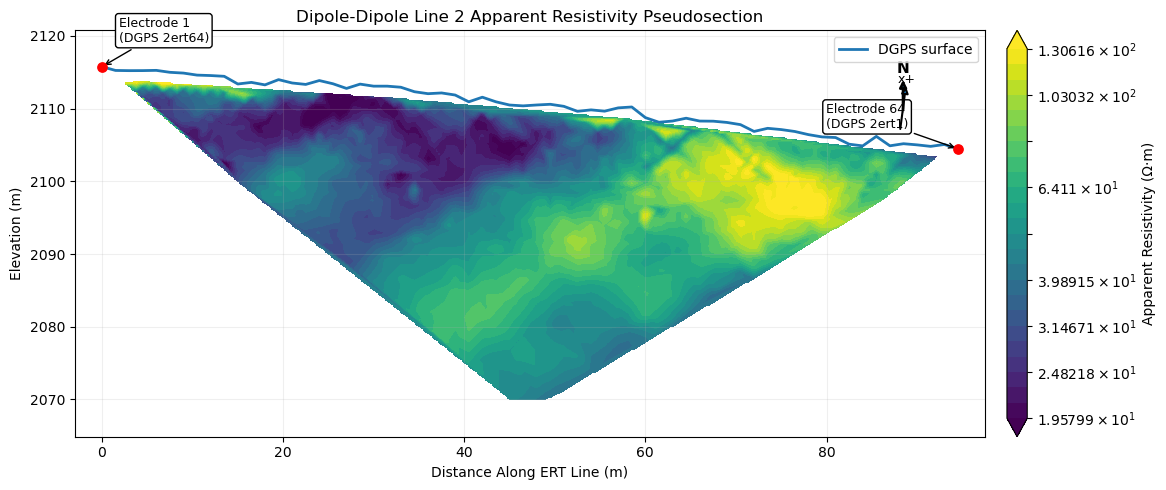

Increasing ERT x orientation: Line 1 = 340.4°, Line 2 = 7.5° clockwise from north


In [12]:
def line_bearing(profile):
    '''Bearing clockwise from geographic north of INCREASING ERT x.'''
    lat1, lon1 = np.radians(profile.loc[0, ["Latitude", "Longitude"]].to_numpy(dtype=float))
    lat2, lon2 = np.radians(profile.loc[len(profile)-1, ["Latitude", "Longitude"]].to_numpy(dtype=float))
    dlon = lon2 - lon1
    east = np.sin(dlon) * np.cos(lat2)
    north = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
    return float((np.degrees(np.arctan2(east, north)) + 360) % 360)


def add_orientation_inset(ax, bearing):
    compass = ax.inset_axes([0.86, 0.72, 0.10, 0.18])
    compass.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2))
    compass.set_aspect("equal")
    compass.axis("off")
    compass.annotate("", xy=(0, 1), xytext=(0, -0.15),
                     arrowprops=dict(arrowstyle="-|>", linewidth=2))
    compass.text(0, 1.05, "N", ha="center", va="bottom",
                 fontsize=11, fontweight="bold")
    theta = np.radians(90 - bearing)
    dx, dy = 0.8 * np.cos(theta), 0.8 * np.sin(theta)
    compass.annotate("", xy=(dx, dy), xytext=(-dx, -dy),
                     arrowprops=dict(arrowstyle="-|>", linewidth=1.5))
    compass.text(dx * 1.15, dy * 1.15, "x+",
                 ha="center", va="center", fontsize=9)


def plot_smooth_pseudosection(ert, profile, line, n_x=400, n_y=250):
    plot_df = ert.loc[
        np.isfinite(ert["apparent_resistivity"])
        & np.isfinite(ert["distance_m"])
        & np.isfinite(ert["ert_elevation_m"])
        & (ert["apparent_resistivity"] > 0)
    ].copy()
    if len(plot_df) < 4:
        raise ValueError(f"Line {line}: too few valid apparent-resistivity measurements")

    xi = np.linspace(profile["distance_m"].min(), profile["distance_m"].max(), n_x)
    yi = np.linspace(plot_df["ert_elevation_m"].min(), profile["elevation_m"].max(), n_y)
    XI, YI = np.meshgrid(xi, yi)
    # Linear interpolation, matching the original notebook. No measurement dots.
    ZI = griddata((plot_df["distance_m"], plot_df["ert_elevation_m"]),
                  plot_df["apparent_resistivity"], (XI, YI), method="linear")
    surface = np.interp(xi, profile["distance_m"], profile["elevation_m"])
    ZI[YI > surface[np.newaxis, :]] = np.nan

    vmin, vmax = np.nanpercentile(plot_df["apparent_resistivity"], [2, 98])
    if not (np.isfinite(vmin) and np.isfinite(vmax) and 0 < vmin < vmax):
        raise ValueError(f"Line {line}: invalid resistivity color scale")
    levels = np.geomspace(vmin, vmax, 25)
    bearing = line_bearing(profile)

    fig, ax = plt.subplots(figsize=(12, 5))
    add_orientation_inset(ax, bearing)
    contours = ax.contourf(XI, YI, ZI, levels=levels,
                            norm=LogNorm(vmin=vmin, vmax=vmax), extend="both")
    ax.plot(profile["distance_m"], profile["elevation_m"],
            linewidth=2, label="DGPS surface")
    fig.colorbar(contours, ax=ax, pad=0.02).set_label("Apparent Resistivity (Ω·m)")
    ax.set(xlabel="Distance Along ERT Line (m)", ylabel="Elevation (m)",
           title=f"Dipole-Dipole Line {line} Apparent Resistivity Pseudosection")
    ax.legend()
    ax.grid(alpha=0.2)

    for idx, x_offset in [(0, (12, 18)), (-1, (-95, 15))]:
        point = profile.iloc[idx]
        x, y = float(point["distance_m"]), float(point["elevation_m"])
        ax.scatter(x, y, s=45, color="red", zorder=5)
        ax.annotate(f"Electrode {int(point['electrode'])}\n(DGPS {point['Name']})",
                    xy=(x, y), xytext=x_offset, textcoords="offset points",
                    fontsize=9, bbox=dict(boxstyle="round,pad=0.25",
                                          fc="white", ec="black"),
                    arrowprops=dict(arrowstyle="->"))

    y_low, y_high = ax.get_ylim()
    ax.set_ylim(y_low - 5, y_high + 5)
    ax.set_xlim(-3, (N_ELECTRODES - 1) * ELECTRODE_SPACING_M + 3)
    fig.tight_layout()
    save_figure(fig, f"DipoleDipole_Line{line}_Pseudosection.png")
    plt.show()
    return bearing


bearing1 = plot_smooth_pseudosection(dd1, dgps1, line=1)
bearing2 = plot_smooth_pseudosection(dd2, dgps2, line=2)
print(f"Increasing ERT x orientation: Line 1 = {bearing1:.1f}°, "
      f"Line 2 = {bearing2:.1f}° clockwise from north")

## 8. Export processing results for QC and future inversion

In [13]:
# Export all four ABEM surveys without discarding rows. The gradient arrays are
# NOT assigned to DGPS Line 1 or Line 2, because that correspondence is not
# established in the original notebook and must be checked before inversion.
if SAVE_TABLES:
    for survey_name, data in surveys.items():
        outpath = OUTPUT_DIR / f"{survey_name}_processed.csv"
        data.to_csv(outpath, index=False)
        print(f"Saved: {outpath.name} ({len(data)} rows)")
    qc_table.to_csv(OUTPUT_DIR / "ERT_basic_QC.csv", index=False)
    print("Saved: ERT_basic_QC.csv")

print("\nData objects available for a separate inversion notebook:")
print("  dgps1, dgps2: aligned electrode locations and DGPS elevations")
print("  dd1, dd2: raw ABEM resistance and computed pseudosection attributes")
print("  gradient_05m, gradient_15m: gradient arrays (DGPS alignment not yet verified)")
print("  surveys: dictionary containing all four ERT datasets")

Saved: dd1_processed.csv (1980 rows)
Saved: dd2_processed.csv (1980 rows)
Saved: gradient_05m_processed.csv (1565 rows)
Saved: gradient_15m_processed.csv (1565 rows)
Saved: ERT_basic_QC.csv

Data objects available for a separate inversion notebook:
  dgps1, dgps2: aligned electrode locations and DGPS elevations
  dd1, dd2: raw ABEM resistance and computed pseudosection attributes
  gradient_05m, gradient_15m: gradient arrays (DGPS alignment not yet verified)
  surveys: dictionary containing all four ERT datasets
